# Airbnb NYC Market Analytics
## End-to-End Data Analysis | Final Internship Project

**Dataset:** `AB_NYC_2019.csv` supplied with the internship task  
**Scope:** Descriptive analysis of the listing-level Airbnb NYC snapshot  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

This notebook is based exclusively on the provided dataset. It does not download, merge, or substitute any external dataset.

### Analysis principles
- Preserve the raw data in `df_raw`.
- Document every cleaning decision.
- Treat unusual prices as potential outliers, not automatic errors.
- Use medians and percentiles for skewed price distributions.
- Interpret reviews and availability as **proxies**, not direct booking or revenue measures.
- The dataset is a 2019 snapshot, so it cannot support a genuine time-series trend analysis of bookings or revenue.
- Findings are descriptive associations; they do not establish causation.

## 0. Setup

The notebook uses commonly available Python data-analysis libraries. The final ZIP packaging/download step is optional; the analysis and individual exports are created before that step.

In [1]:
# If a package is missing in your environment, uncomment the next line:
# %pip install pandas numpy matplotlib seaborn

import os
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid", palette="deep")
OUTPUT_DIR = Path("airbnb_nyc_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Setup complete.")
print("Output folder:", OUTPUT_DIR.resolve())

Setup complete.
Output folder: D:\Voltix Internship\FinalTask\airbnb_nyc_outputs


## 1. Load the provided dataset

Upload or select the exact CSV attached to the internship task. Do not use another dataset. The notebook accepts the provided `AB_NYC_2019.csv` file and checks that the expected columns are present.

In [2]:
from pathlib import Path

candidate_files = list(Path(".").glob("*.csv"))

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    print("Upload the internship-provided Airbnb NYC CSV file.")
    uploaded = files.upload()
    csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]
    if not csv_files:
        raise FileNotFoundError("No CSV file was uploaded. Please upload the provided AB_NYC_2019.csv file.")
    if len(csv_files) > 1:
        print("CSV files uploaded:", csv_files)
        selected_file = input("Type the exact filename to use: ").strip()
        if selected_file not in csv_files:
            raise ValueError("The selected filename was not among the uploaded CSV files.")
    else:
        selected_file = csv_files[0]
else:
    csv_files = [p.name for p in candidate_files]
    if not csv_files:
        selected_file = input("Enter the path to the internship-provided CSV file: ").strip()
        if not Path(selected_file).exists():
            raise FileNotFoundError(f"File not found: {selected_file}")
    elif len(csv_files) == 1:
        selected_file = csv_files[0]
    else:
        print("CSV files found:", csv_files)
        selected_file = input("Type the exact filename of the internship-provided dataset: ").strip()
        if selected_file not in csv_files:
            raise ValueError("The selected filename was not found in the current folder.")

print("Selected file:", selected_file)

# Read the file; keep a raw copy unchanged for reference.
df_raw = pd.read_csv(selected_file)
df = df_raw.copy(deep=True)

print("Raw dataset loaded successfully.")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]:,}")
display(df.head())

Selected file: AB_NYC_2019.csv
Raw dataset loaded successfully.
Rows: 48,895 | Columns: 16


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.65,-73.97,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75,-73.98,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.81,-73.94,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.69,-73.96,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.80,-73.94,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


## 2. Data understanding

First inspect the dimensions, column names, data types, sample records, and descriptive statistics. This section documents what the dataset actually contains before any cleaning decisions are made.

In [3]:
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.rename("dtype").to_frame())

print("\nDataset information:")
df.info()

print("\nNumerical summary:")
display(df.describe(include=[np.number]).T)

print("\nCategorical summary:")
display(df.describe(include=["object"]).T)

Shape: (48895, 16)

Column names:
['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Data types:


,dtype
id,int64
name,object
host_id,int64
host_name,object
neighbourhood_group,object
neighbourhood,object
latitude,float64
longitude,float64
room_type,object
price,int64



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_revie

,count,mean,std,min,25%,50%,75%,max
id,"48,895.00","19,017,143.24","10,983,108.39","2,539.00","9,471,945.00","19,677,284.00","29,152,178.50","36,487,245.00"
host_id,"48,895.00","67,620,010.65","78,610,967.03","2,438.00","7,822,033.00","30,793,816.00","107,434,423.00","274,321,313.00"
latitude,"48,895.00",40.73,0.05,40.50,40.69,40.72,40.76,40.91
longitude,"48,895.00",-73.95,0.05,-74.24,-73.98,-73.96,-73.94,-73.71
price,"48,895.00",152.72,240.15,0.00,69.00,106.00,175.00,"10,000.00"
minimum_nights,"48,895.00",7.03,20.51,1.00,1.00,3.00,5.00,"1,250.00"
number_of_reviews,"48,895.00",23.27,44.55,0.00,1.00,5.00,24.00,629.00
reviews_per_month,"38,843.00",1.37,1.68,0.01,0.19,0.72,2.02,58.50
calculated_host_listings_count,"48,895.00",7.14,32.95,1.00,1.00,1.00,2.00,327.00
availability_365,"48,895.00",112.78,131.62,0.00,0.00,45.00,227.00,365.00



Categorical summary:


,count,unique,top,freq
name,48879,47905,Hillside Hotel,18
host_name,48874,11452,Michael,417
neighbourhood_group,48895,5,Manhattan,21661
neighbourhood,48895,221,Williamsburg,3920
room_type,48895,3,Entire home/apt,25409
last_review,38843,1764,2019-06-23,1413


In [4]:
# Build a compact column dictionary for the expected Airbnb NYC 2019 fields.
column_dictionary = {
    "id": "Unique identifier for a listing",
    "name": "Listing title",
    "host_id": "Identifier for the host",
    "host_name": "Host display name",
    "neighbourhood_group": "NYC borough/group",
    "neighbourhood": "Neighborhood within the borough",
    "latitude": "Listing latitude",
    "longitude": "Listing longitude",
    "room_type": "Type of accommodation offered",
    "price": "Listed nightly price (currency/unit as represented in source)",
    "minimum_nights": "Minimum number of nights required per booking",
    "number_of_reviews": "Total number of reviews recorded",
    "last_review": "Date of the most recent review",
    "reviews_per_month": "Average reviews per month, where available",
    "calculated_host_listings_count": "Number of listings attributed to the host",
    "availability_365": "Number of days available in the next 365 days"
}

dictionary_rows = []
for col in df.columns:
    dictionary_rows.append({
        "column": col,
        "meaning": column_dictionary.get(col, "Review source documentation / meaning"),
        "dtype": str(df[col].dtype),
        "non_null": int(df[col].notna().sum()),
        "missing": int(df[col].isna().sum()),
        "unique_values": int(df[col].nunique(dropna=True))
    })

column_dictionary_df = pd.DataFrame(dictionary_rows)
display(column_dictionary_df)

,column,meaning,dtype,non_null,missing,unique_values
0,id,Unique identifier for a listing,int64,48895,0,48895
1,name,Listing title,object,48879,16,47905
2,host_id,Identifier for the host,int64,48895,0,37457
3,host_name,Host display name,object,48874,21,11452
4,neighbourhood_group,NYC borough/group,object,48895,0,5
5,neighbourhood,Neighborhood within the borough,object,48895,0,221
6,latitude,Listing latitude,float64,48895,0,19048
7,longitude,Listing longitude,float64,48895,0,14718
8,room_type,Type of accommodation offered,object,48895,0,3
9,price,Listed nightly price (currency/unit as represe...,int64,48895,0,674


### 2.1 Business questions

This listing-level dataset can help answer:
1. Where are Airbnb listings concentrated across NYC boroughs and neighborhoods?
2. Which room types dominate the available supply?
3. How do listed prices vary by borough, neighborhood, and room type?
4. How are price, review activity, host portfolio size, and availability associated?
5. Which neighborhoods have a large supply and how do their typical prices compare?

**Limitations:** The data does not contain actual booking transactions, occupancy, revenue, guest ratings, or a complete booking-date history. Therefore, we must not claim that a listing or neighborhood generates the highest revenue, occupancy, or customer satisfaction.

In [5]:
expected_columns = [
    "id", "name", "host_id", "host_name", "neighbourhood_group",
    "neighbourhood", "latitude", "longitude", "room_type", "price",
    "minimum_nights", "number_of_reviews", "last_review",
    "reviews_per_month", "calculated_host_listings_count", "availability_365"
]

missing_expected = [c for c in expected_columns if c not in df.columns]
extra_columns = [c for c in df.columns if c not in expected_columns]

print("Expected columns missing from this file:", missing_expected if missing_expected else "None")
print("Additional columns:", extra_columns if extra_columns else "None")

if "price" not in df.columns or "room_type" not in df.columns:
    raise ValueError(
        "This file does not contain the expected Airbnb NYC fields (at minimum, 'price' and 'room_type'). "
        "Check that you uploaded the internship-provided dataset."
    )

Expected columns missing from this file: None
Additional columns: None


## 3. Data quality audit — before cleaning

We inspect missing values, exact duplicates, repeated listing IDs, data types, category consistency, and suspicious numeric values. The audit is kept separate from cleaning so that issues are documented before decisions are applied.

In [6]:
# Missing values by column
missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "non_missing_count": df.notna().sum()
}).sort_values("missing_percent", ascending=False)

display(missing_report)
missing_report.to_csv("airbnb_nyc_missing_values.csv", index=True)

print("Exact duplicate rows:", int(df.duplicated().sum()))
if "id" in df.columns:
    print("Rows with duplicated listing ID (excluding null IDs):",
          int(df["id"].duplicated().sum()))

,missing_count,missing_percent,non_missing_count
last_review,10052,20.56,38843
reviews_per_month,10052,20.56,38843
host_name,21,0.04,48874
name,16,0.03,48879
neighbourhood_group,0,0.00,48895
neighbourhood,0,0.00,48895
id,0,0.00,48895
host_id,0,0.00,48895
longitude,0,0.00,48895
latitude,0,0.00,48895


Exact duplicate rows: 0
Rows with duplicated listing ID (excluding null IDs): 0


In [7]:
# Numeric range audit: counts that deserve inspection, not automatic deletion.
numeric_audit = []
for col in df.select_dtypes(include=np.number).columns:
    s = df[col].dropna()
    numeric_audit.append({
        "column": col,
        "min": s.min() if len(s) else np.nan,
        "median": s.median() if len(s) else np.nan,
        "max": s.max() if len(s) else np.nan,
        "negative_count": int((s < 0).sum()),
        "zero_count": int((s == 0).sum()),
        "positive_count": int((s > 0).sum())
    })

numeric_audit_df = pd.DataFrame(numeric_audit)
display(numeric_audit_df)

,column,min,median,max,negative_count,zero_count,positive_count
0,id,"2,539.00","19,677,284.00","36,487,245.00",0,0,48895
1,host_id,"2,438.00","30,793,816.00","274,321,313.00",0,0,48895
2,latitude,40.50,40.72,40.91,0,0,48895
3,longitude,-74.24,-73.96,-73.71,48895,0,0
4,price,0.00,106.00,"10,000.00",0,11,48884
5,minimum_nights,1.00,3.00,"1,250.00",0,0,48895
6,number_of_reviews,0.00,5.00,629.00,0,10052,38843
7,reviews_per_month,0.01,0.72,58.50,0,0,38843
8,calculated_host_listings_count,1.00,1.00,327.00,0,0,48895
9,availability_365,0.00,45.00,365.00,0,17533,31362


In [8]:
# Check the actual categories and date range before standardizing values.
for col in ["neighbourhood_group", "room_type"]:
    if col in df.columns:
        print(f"\nUnique values in {col} ({df[col].nunique(dropna=True)}):")
        display(df[col].value_counts(dropna=False).to_frame("count").head(30))

if "last_review" in df.columns:
    print("\nSample raw last_review values:")
    display(df["last_review"].dropna().astype(str).head(10).to_frame())


Unique values in neighbourhood_group (5):


,count
neighbourhood_group,
Manhattan,21661
Brooklyn,20104
Queens,5666
Bronx,1091
Staten Island,373



Unique values in room_type (3):


,count
room_type,
Entire home/apt,25409
Private room,22326
Shared room,1160



Sample raw last_review values:


,last_review
0,2018-10-19
1,2019-05-21
3,2019-07-05
4,2018-11-19
5,2019-06-22
6,2017-10-05
7,2019-06-24
8,2017-07-21
9,2019-06-09
10,2019-06-22


## 4. Cleaning and preparation

### Cleaning policy
1. Keep `df_raw` unchanged.
2. Remove exact duplicate rows only; report the number removed.
3. Trim leading/trailing whitespace in text columns.
4. Convert numeric fields and `last_review` to suitable data types.
5. Keep missing review dates/rates missing unless the analysis has a defensible reason to impute them.
6. Flag zero/non-positive prices and implausible values for review.
7. Retain price outliers in the cleaned dataset; exclude non-positive prices from price comparisons and disclose this filter.

In [9]:
df_clean = df_raw.copy(deep=True)
cleaning_log = []

def log_step(step, before_rows, after_rows, note):
    cleaning_log.append({
        "step": step,
        "rows_before": int(before_rows),
        "rows_after": int(after_rows),
        "rows_removed": int(before_rows - after_rows),
        "note": note
    })

# 4.1 Remove exact duplicate rows only.
before = len(df_clean)
df_clean = df_clean.drop_duplicates().copy()
log_step(
    "Remove exact duplicate rows",
    before, len(df_clean),
    "Only rows identical across all columns were removed."
)

# 4.2 Strip whitespace in text columns.
text_cols = df_clean.select_dtypes(include=["object", "string"]).columns.tolist()
for col in text_cols:
    df_clean[col] = df_clean[col].map(
        lambda x: x.strip() if isinstance(x, str) else x
    )
cleaning_log.append({
    "step": "Trim text whitespace",
    "rows_before": int(len(df_clean)),
    "rows_after": int(len(df_clean)),
    "rows_removed": 0,
    "note": f"Trimmed leading/trailing whitespace in {len(text_cols)} text columns."
})

# 4.3 Convert expected numeric columns where present.
numeric_cols_expected = [
    "id", "host_id", "latitude", "longitude", "price", "minimum_nights",
    "number_of_reviews", "reviews_per_month",
    "calculated_host_listings_count", "availability_365"
]
for col in numeric_cols_expected:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# 4.4 Convert dates.
if "last_review" in df_clean.columns:
    df_clean["last_review"] = pd.to_datetime(df_clean["last_review"], errors="coerce")

# 4.5 Standardize categorical text casing conservatively.
for col in ["neighbourhood_group", "room_type"]:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].map(
            lambda x: x.strip() if isinstance(x, str) else x
        )

print("Cleaning steps completed.")
display(pd.DataFrame(cleaning_log))

Cleaning steps completed.


,step,rows_before,rows_after,rows_removed,note
0,Remove exact duplicate rows,48895,48895,0,Only rows identical across all columns were re...
1,Trim text whitespace,48895,48895,0,Trimmed leading/trailing whitespace in 6 text ...


In [10]:
# 4.6 Flag suspicious values for investigation.
# We preserve these rows in the main cleaned dataset unless clearly invalid.
if "price" in df_clean.columns:
    df_clean["flag_price_nonpositive"] = df_clean["price"].notna() & (df_clean["price"] <= 0)

if "minimum_nights" in df_clean.columns:
    df_clean["flag_minimum_nights_nonpositive"] = (
        df_clean["minimum_nights"].notna() & (df_clean["minimum_nights"] <= 0)
    )

if "availability_365" in df_clean.columns:
    df_clean["flag_availability_out_of_range"] = (
        df_clean["availability_365"].notna()
        & ~df_clean["availability_365"].between(0, 365)
    )

if {"latitude", "longitude"}.issubset(df_clean.columns):
    df_clean["flag_invalid_coordinates"] = (
        df_clean["latitude"].notna()
        & df_clean["longitude"].notna()
        & (
            ~df_clean["latitude"].between(-90, 90)
            | ~df_clean["longitude"].between(-180, 180)
        )
    )

flag_cols = [c for c in df_clean.columns if c.startswith("flag_")]
if flag_cols:
    display(df_clean[flag_cols].sum().rename("flagged_rows").to_frame())
else:
    print("No standard flag columns could be created from this file.")

,flagged_rows
flag_price_nonpositive,11
flag_minimum_nights_nonpositive,0
flag_availability_out_of_range,0
flag_invalid_coordinates,0


In [11]:
# 4.7 Outlier flags using IQR. This flags values; it does not remove them.
def iqr_bounds(series):
    s = series.dropna()
    if s.empty:
        return np.nan, np.nan
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

if "price" in df_clean.columns:
    price_lower, price_upper = iqr_bounds(df_clean["price"])
    df_clean["flag_price_iqr_outlier"] = (
        df_clean["price"].notna()
        & ((df_clean["price"] < price_lower) | (df_clean["price"] > price_upper))
    )
    print(f"Price IQR lower bound: {price_lower:,.2f}")
    print(f"Price IQR upper bound: {price_upper:,.2f}")
    print("Price IQR outlier count:", int(df_clean["flag_price_iqr_outlier"].sum()))
    print("Note: outliers remain in the dataset for transparent analysis.")

Price IQR lower bound: -90.00
Price IQR upper bound: 334.00
Price IQR outlier count: 2972
Note: outliers remain in the dataset for transparent analysis.


### 4.1 Cleaning decisions

For the supplied data, the initial run found no exact duplicate rows and no repeated listing IDs. It identified 11 listings with a price of zero, plus 2,972 IQR-flagged price outliers. The outlier flag is a statistical screening rule, not proof that a listing is erroneous. Zero-price listings are retained in the cleaned file but excluded from price summaries.

In [12]:
# Show suspicious records for manual review (if any).
review_flag_cols = [c for c in df_clean.columns if c.startswith("flag_")]
if review_flag_cols:
    flagged_mask = df_clean[review_flag_cols].fillna(False).astype(bool).any(axis=1)
    print("Rows with at least one quality flag:", int(flagged_mask.sum()))
    display(df_clean.loc[flagged_mask].head(20))
else:
    print("No flags available.")

Rows with at least one quality flag: 2983


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,flag_price_nonpositive,flag_minimum_nights_nonpositive,flag_availability_out_of_range,flag_invalid_coordinates,flag_price_iqr_outlier
61,15396,Sunny & Spacious Chelsea Apartment,60278,Petra,Manhattan,Chelsea,40.75,-74.00,Entire home/apt,375,180,5,2018-11-03,0.12,1,180,False,False,False,False,True
85,19601,perfect for a family or small group,74303,Maggie,Brooklyn,Brooklyn Heights,40.70,-73.99,Entire home/apt,800,1,25,2016-08-04,0.24,1,7,False,False,False,False,True
103,23686,2000 SF 3br 2bath West Village private townhouse,93790,Ann,Manhattan,West Village,40.73,-74.00,Entire home/apt,500,4,46,2019-05-18,0.55,2,243,False,False,False,False,True
114,26933,2 BR / 2 Bath Duplex Apt with patio! East Village,72062,Bruce,Manhattan,East Village,40.73,-73.98,Entire home/apt,350,2,7,2017-08-09,0.06,4,298,False,False,False,False,True
121,27659,3 Story Town House in Park Slope,119588,Vero,Brooklyn,South Slope,40.66,-73.98,Entire home/apt,400,2,16,2018-12-30,0.24,2,216,False,False,False,False,True
158,38663,Luxury Brownstone in Boerum Hill,165789,Sarah,Brooklyn,Boerum Hill,40.69,-73.98,Entire home/apt,475,3,23,2018-12-31,0.27,1,230,False,False,False,False,True
181,45910,Beautiful Queens Brownstone! - 5BR,204539,Mark,Queens,Ridgewood,40.70,-73.90,Entire home/apt,350,8,10,2019-05-12,0.11,5,365,False,False,False,False,True
233,60164,"Beautiful, elegant 3 bed SOHO loft",289653,Harrison,Manhattan,SoHo,40.72,-74.00,Entire home/apt,500,4,94,2019-06-23,0.99,1,329,False,False,False,False,True
242,61224,Huge Chelsea Loft,291112,Frank,Manhattan,Chelsea,40.74,-74.00,Entire home/apt,500,2,35,2017-07-27,0.34,1,348,False,False,False,False,True
263,63693,Cottage in the Village,306545,Olivia,Manhattan,East Village,40.72,-73.98,Entire home/apt,390,5,143,2019-06-19,1.38,2,316,False,False,False,False,True


In [13]:
# Create a final quality summary after type conversion and duplicate removal.
quality_report = pd.DataFrame({
    "dtype": df_clean.dtypes.astype(str),
    "missing_count": df_clean.isna().sum(),
    "missing_percent": (df_clean.isna().mean() * 100).round(2),
    "unique_values": df_clean.nunique(dropna=True)
}).sort_values("missing_percent", ascending=False)

display(quality_report)
quality_report.to_csv("airbnb_nyc_data_quality_report.csv", index=True)

,dtype,missing_count,missing_percent,unique_values
last_review,datetime64[ns],10052,20.56,1764
reviews_per_month,float64,10052,20.56,937
host_name,object,21,0.04,11452
name,object,16,0.03,47894
id,int64,0,0.00,48895
neighbourhood_group,object,0,0.00,5
host_id,int64,0,0.00,37457
longitude,float64,0,0.00,14718
neighbourhood,object,0,0.00,221
room_type,object,0,0.00,3


## 5. Feature engineering

Derived fields support segmentation without replacing original fields:
- **Price segment:** quartile-based categories for positive prices.
- **Host portfolio segment:** based on the dataset's `calculated_host_listings_count`.
- **Review activity segment:** quartile-based where enough distinct values exist.

These segments are descriptive, not quality scores or performance rankings.

In [14]:
# Copy the cleaned table for analysis-specific derived fields.
df_analysis = df_clean.copy()

# Price segment using quartiles; duplicate edges are handled safely.
if "price" in df_analysis.columns:
    valid_price = df_analysis["price"].dropna()
    valid_price = valid_price[valid_price > 0]
    if valid_price.nunique() >= 4 and len(valid_price) > 0:
        try:
            bins = valid_price.quantile([0, 0.25, 0.50, 0.75, 1.0]).values
            bins = np.unique(bins)
            labels = ["Lower price", "Mid-low price", "Mid-high price", "Upper price"][:len(bins)-1]
            df_analysis["price_segment"] = pd.cut(
                df_analysis["price"], bins=bins, labels=labels,
                include_lowest=True, duplicates="drop"
            )
        except Exception as e:
            print("Could not create price_segment:", e)

# Host portfolio size, based on number of listings attributed to each host.
if "calculated_host_listings_count" in df_analysis.columns:
    df_analysis["host_portfolio_segment"] = pd.cut(
        df_analysis["calculated_host_listings_count"],
        bins=[-np.inf, 1, 5, 10, np.inf],
        labels=["1 listing", "2–5 listings", "6–10 listings", "11+ listings"]
    )

# Review activity groups based on quartiles, only if values vary.
if "reviews_per_month" in df_analysis.columns:
    s = df_analysis["reviews_per_month"].dropna()
    if len(s) > 0 and s.nunique() >= 3:
        try:
            df_analysis["review_activity_segment"] = pd.qcut(
                df_analysis["reviews_per_month"],
                q=4,
                labels=["Low", "Moderate", "High", "Very high"],
                duplicates="drop"
            )
        except ValueError:
            print("Review activity groups could not be created because of tied values.")

display(df_analysis.head())

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,flag_price_nonpositive,flag_minimum_nights_nonpositive,flag_availability_out_of_range,flag_invalid_coordinates,flag_price_iqr_outlier,price_segment,host_portfolio_segment,review_activity_segment
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.65,-73.97,Private room,149,1,9,2018-10-19,0.21,6,365,False,False,False,False,False,Mid-high price,6–10 listings,Moderate
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75,-73.98,Entire home/apt,225,1,45,2019-05-21,0.38,2,355,False,False,False,False,False,Upper price,2–5 listings,Moderate
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.81,-73.94,Private room,150,3,0,NaT,NaN,1,365,False,False,False,False,False,Mid-high price,1 listing,NaN
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.69,-73.96,Entire home/apt,89,1,270,2019-07-05,4.64,1,194,False,False,False,False,False,Mid-low price,1 listing,Very high
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.80,-73.94,Entire home/apt,80,10,9,2018-11-19,0.10,1,0,False,False,False,False,False,Mid-low price,1 listing,Low


## 6. Exploratory Data Analysis

Each analysis is tied to a business question. The chart is followed by a short data-driven observation where possible. Any percentile-limited chart is only a display choice; the underlying records remain available.

### 6.1 Market overview and KPIs

In [15]:
total_listings = len(df_analysis)
unique_hosts = df_analysis["host_id"].nunique() if "host_id" in df_analysis.columns else np.nan
median_price = df_analysis.loc[df_analysis["price"] > 0, "price"].median() if "price" in df_analysis.columns else np.nan
mean_price = df_analysis.loc[df_analysis["price"] > 0, "price"].mean() if "price" in df_analysis.columns else np.nan
total_reviews = df_analysis["number_of_reviews"].sum() if "number_of_reviews" in df_analysis.columns else np.nan
median_reviews = df_analysis["number_of_reviews"].median() if "number_of_reviews" in df_analysis.columns else np.nan
median_availability = df_analysis["availability_365"].median() if "availability_365" in df_analysis.columns else np.nan

kpis = pd.DataFrame({
    "Metric": [
        "Listing rows after exact-deduplication",
        "Unique hosts",
        "Median positive price",
        "Mean positive price",
        "Total recorded reviews",
        "Median reviews per listing",
        "Median availability (days)"
    ],
    "Value": [
        total_listings, unique_hosts, median_price, mean_price,
        total_reviews, median_reviews, median_availability
    ]
})
display(kpis)

,Metric,Value
0,Listing rows after exact-deduplication,"48,895.00"
1,Unique hosts,"37,457.00"
2,Median positive price,106.00
3,Mean positive price,152.76
4,Total recorded reviews,"1,138,005.00"
5,Median reviews per listing,5.00
6,Median availability (days),45.00


,neighbourhood_group,listing_count
0,Manhattan,21661
1,Brooklyn,20104
2,Queens,5666
3,Bronx,1091
4,Staten Island,373


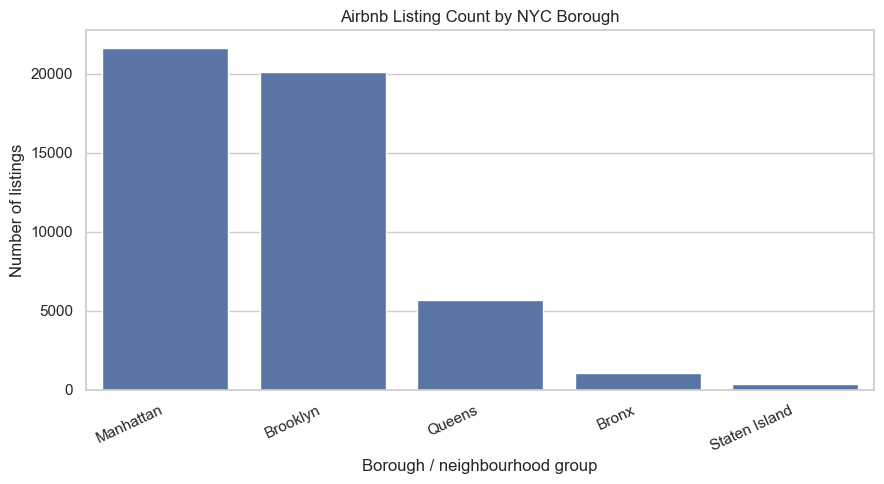

In [16]:
# Listing counts by borough / neighbourhood group
if "neighbourhood_group" in df_analysis.columns:
    borough_counts = (
        df_analysis["neighbourhood_group"]
        .fillna("Missing")
        .value_counts()
        .rename_axis("neighbourhood_group")
        .reset_index(name="listing_count")
    )
    display(borough_counts)

    plt.figure(figsize=(9, 5))
    sns.barplot(data=borough_counts, x="neighbourhood_group", y="listing_count")
    plt.title("Airbnb Listing Count by NYC Borough")
    plt.xlabel("Borough / neighbourhood group")
    plt.ylabel("Number of listings")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "01_listings_by_borough.png", dpi=180, bbox_inches="tight")
    plt.show()

,room_type,listing_count
0,Entire home/apt,25409
1,Private room,22326
2,Shared room,1160


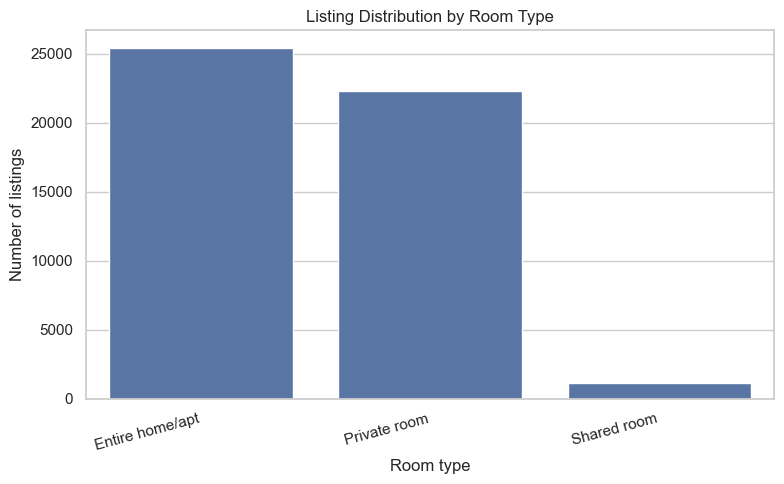

In [17]:
# Room type distribution
if "room_type" in df_analysis.columns:
    room_counts = (
        df_analysis["room_type"]
        .fillna("Missing")
        .value_counts()
        .rename_axis("room_type")
        .reset_index(name="listing_count")
    )
    display(room_counts)

    plt.figure(figsize=(8, 5))
    sns.barplot(data=room_counts, x="room_type", y="listing_count")
    plt.title("Listing Distribution by Room Type")
    plt.xlabel("Room type")
    plt.ylabel("Number of listings")
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "02_room_type_distribution.png", dpi=180, bbox_inches="tight")
    plt.show()

### 6.2 Price distribution and pricing by location

Positive-price listing count: 48884
Price percentiles:


,price
0.25,69.00
0.50,106.00
0.75,175.00
0.90,269.00
0.95,355.00
0.99,799.00


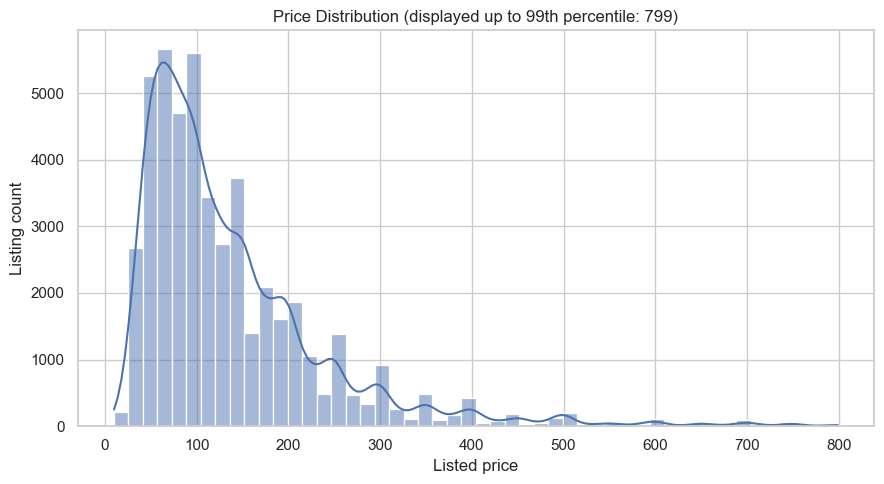

Chart excludes prices above the 99th percentile for display readability only; source rows are not deleted.


In [18]:
# Price distribution: inspect valid positive prices and use a percentile-limited view for readability.
if "price" in df_analysis.columns:
    valid_prices = df_analysis.loc[df_analysis["price"].notna() & (df_analysis["price"] > 0), "price"]
    print("Positive-price listing count:", len(valid_prices))
    if len(valid_prices):
        print("Price percentiles:")
        display(valid_prices.quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).rename("price").to_frame())

        display_limit = valid_prices.quantile(0.99)
        plt.figure(figsize=(9, 5))
        sns.histplot(valid_prices[valid_prices <= display_limit], bins=50, kde=True)
        plt.title(f"Price Distribution (displayed up to 99th percentile: {display_limit:,.0f})")
        plt.xlabel("Listed price")
        plt.ylabel("Listing count")
        plt.tight_layout()
        plt.savefig(OUTPUT_DIR / "03_price_distribution.png", dpi=180, bbox_inches="tight")
        plt.show()
        print("Chart excludes prices above the 99th percentile for display readability only; source rows are not deleted.")

,neighbourhood_group,listing_count,median_price,mean_price,p75_price,p90_price
0,Manhattan,21660,150.00,196.88,220.00,333.00
1,Brooklyn,20095,90.00,124.44,150.00,210.00
2,Queens,5666,75.00,99.52,110.00,175.00
3,Staten Island,373,75.00,114.81,110.00,184.00
4,Bronx,1090,65.00,87.58,99.00,145.00


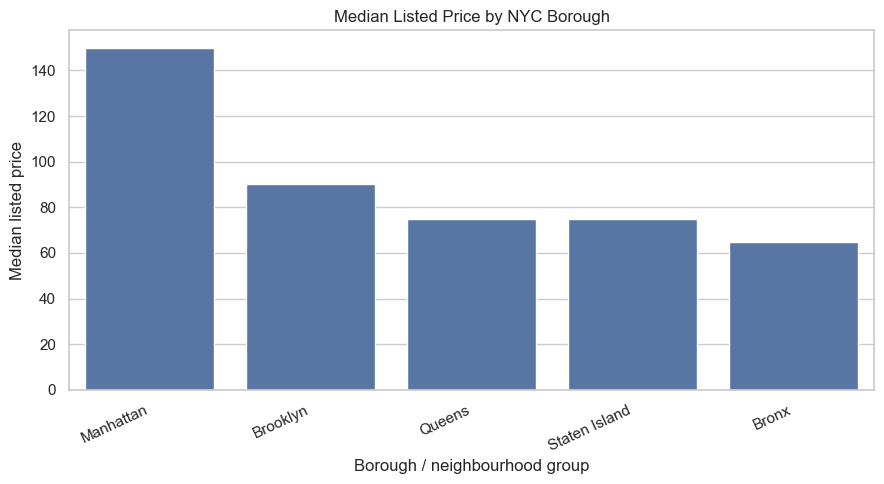

In [19]:
# Compare median and mean prices by borough.
if {"neighbourhood_group", "price"}.issubset(df_analysis.columns):
    price_by_borough = (
        df_analysis.loc[df_analysis["price"] > 0]
        .groupby("neighbourhood_group", dropna=False)
        .agg(
            listing_count=("price", "size"),
            median_price=("price", "median"),
            mean_price=("price", "mean"),
            p75_price=("price", lambda s: s.quantile(0.75)),
            p90_price=("price", lambda s: s.quantile(0.90))
        )
        .sort_values("median_price", ascending=False)
        .reset_index()
    )
    display(price_by_borough)
    price_by_borough.to_csv("airbnb_nyc_borough_summary.csv", index=False)

    plt.figure(figsize=(9, 5))
    sns.barplot(data=price_by_borough, x="neighbourhood_group", y="median_price")
    plt.title("Median Listed Price by NYC Borough")
    plt.xlabel("Borough / neighbourhood group")
    plt.ylabel("Median listed price")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "04_median_price_by_borough.png", dpi=180, bbox_inches="tight")
    plt.show()

,neighbourhood_group,room_type,listing_count,median_price,mean_price
0,Bronx,Entire home/apt,379,100.00,127.51
1,Bronx,Private room,651,54.00,66.89
2,Bronx,Shared room,60,40.00,59.80
3,Brooklyn,Entire home/apt,9558,145.00,178.35
4,Brooklyn,Private room,10126,65.00,76.55
5,Brooklyn,Shared room,411,36.00,50.77
6,Manhattan,Entire home/apt,13198,191.00,249.26
7,Manhattan,Private room,7982,90.00,116.78
8,Manhattan,Shared room,480,69.00,88.98
9,Queens,Entire home/apt,2096,120.00,147.05


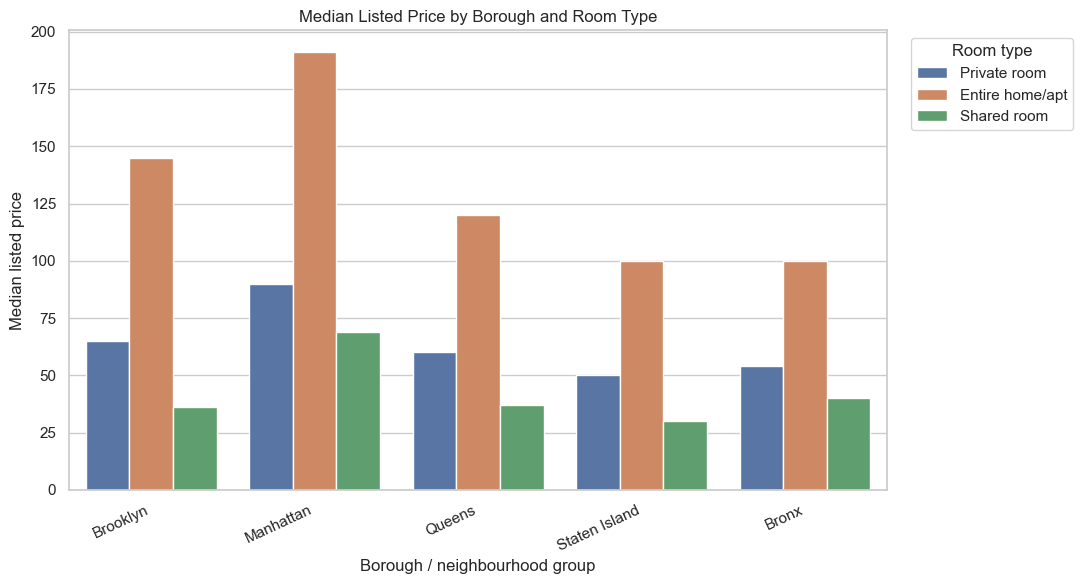

In [20]:
# Price by room type within boroughs
if {"neighbourhood_group", "room_type", "price"}.issubset(df_analysis.columns):
    room_borough_price = (
        df_analysis.loc[df_analysis["price"] > 0]
        .groupby(["neighbourhood_group", "room_type"], dropna=False)
        .agg(
            listing_count=("price", "size"),
            median_price=("price", "median"),
            mean_price=("price", "mean")
        )
        .reset_index()
    )
    display(room_borough_price.sort_values(["neighbourhood_group", "median_price"], ascending=[True, False]))

    plt.figure(figsize=(11, 6))
    sns.barplot(
        data=df_analysis.loc[df_analysis["price"] > 0],
        x="neighbourhood_group", y="price", hue="room_type",
        estimator=np.median, errorbar=None
    )
    plt.title("Median Listed Price by Borough and Room Type")
    plt.xlabel("Borough / neighbourhood group")
    plt.ylabel("Median listed price")
    plt.xticks(rotation=25, ha="right")
    plt.legend(title="Room type", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "05_price_by_borough_and_room_type.png", dpi=180, bbox_inches="tight")
    plt.show()

,neighbourhood_group,neighbourhood,listing_count,median_price,mean_price,median_reviews,median_availability
93,Brooklyn,Williamsburg,3919,105.00,143.84,5.00,3.00
50,Brooklyn,Bedford-Stuyvesant,3710,80.00,107.79,8.00,59.00
105,Manhattan,Harlem,2658,89.00,118.97,8.00,43.00
58,Brooklyn,Bushwick,2462,65.00,84.90,4.00,19.00
124,Manhattan,Upper West Side,1971,150.00,210.92,4.00,10.00
106,Manhattan,Hell's Kitchen,1958,168.00,204.79,5.00,93.50
100,Manhattan,East Village,1853,150.00,186.08,5.00,3.00
123,Manhattan,Upper East Side,1798,149.00,188.95,4.00,30.50
65,Brooklyn,Crown Heights,1564,85.00,112.48,6.00,20.00
112,Manhattan,Midtown,1545,210.00,282.72,2.00,151.00


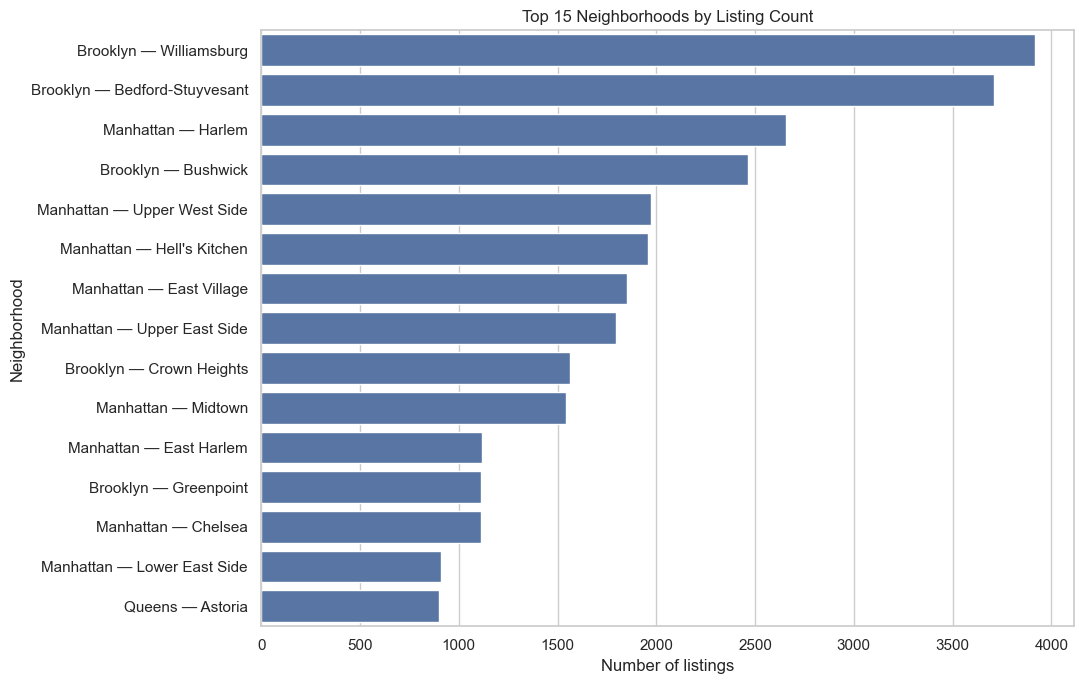

In [21]:
# Neighborhood summary: minimum support threshold reduces noisy comparisons.
if {"neighbourhood", "price"}.issubset(df_analysis.columns):
    group_cols = ["neighbourhood"]
    if "neighbourhood_group" in df_analysis.columns:
        group_cols = ["neighbourhood_group", "neighbourhood"]

    neighborhood_summary = (
        df_analysis.loc[df_analysis["price"] > 0]
        .groupby(group_cols, dropna=False)
        .agg(
            listing_count=("price", "size"),
            median_price=("price", "median"),
            mean_price=("price", "mean"),
            median_reviews=("number_of_reviews", "median") if "number_of_reviews" in df_analysis.columns else ("price", "size"),
            median_availability=("availability_365", "median") if "availability_365" in df_analysis.columns else ("price", "size")
        )
        .reset_index()
    )
    neighborhood_summary = neighborhood_summary.sort_values("listing_count", ascending=False)
    display(neighborhood_summary.head(20))
    neighborhood_summary.to_csv("airbnb_nyc_neighborhood_summary.csv", index=False)

    top_neighborhoods = neighborhood_summary.head(15).copy()
    top_neighborhoods["neighborhood_label"] = top_neighborhoods[group_cols].astype(str).agg(" — ".join, axis=1)
    plt.figure(figsize=(11, 7))
    sns.barplot(data=top_neighborhoods, y="neighborhood_label", x="listing_count")
    plt.title("Top 15 Neighborhoods by Listing Count")
    plt.xlabel("Number of listings")
    plt.ylabel("Neighborhood")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "06_top_neighborhoods_by_count.png", dpi=180, bbox_inches="tight")
    plt.show()

### 6.3 Reviews and availability

`number_of_reviews` and `reviews_per_month` can indicate recorded review activity, but neither is a direct measure of bookings or occupancy. The review variables are highly skewed, and many listings have no recorded reviews. Availability represents days marked available in the next 365 days in this historical snapshot; it should not be interpreted as actual occupancy.

Listings with zero recorded reviews: 10,052 (20.6%)


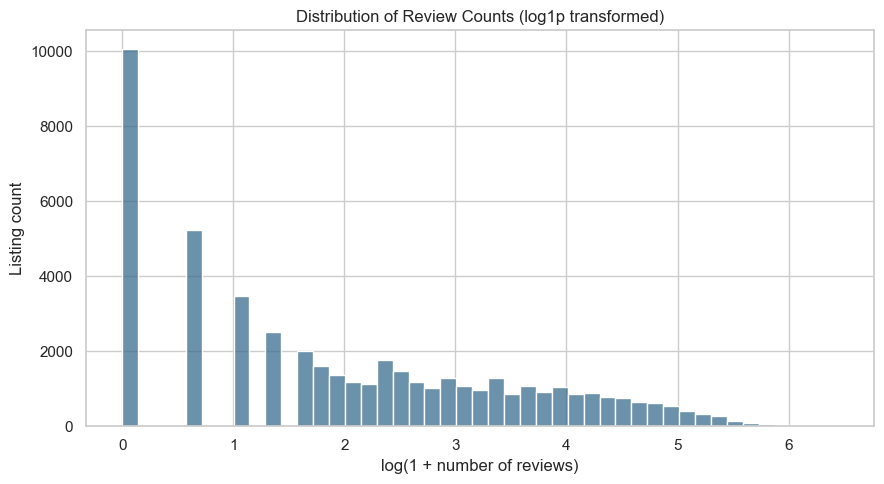

In [22]:
# Review count distribution: log1p makes the highly skewed distribution easier to inspect
if "number_of_reviews" in df_analysis.columns:
    review_counts = df_analysis["number_of_reviews"].dropna()
    print(f"Listings with zero recorded reviews: {(review_counts == 0).sum():,} "
          f"({(review_counts == 0).mean() * 100:.1f}%)")
    plt.figure(figsize=(9, 5))
    sns.histplot(np.log1p(review_counts), bins=45, color="#3B6C8E")
    plt.title("Distribution of Review Counts (log1p transformed)")
    plt.xlabel("log(1 + number of reviews)")
    plt.ylabel("Listing count")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "07_number_of_reviews_distribution.png", dpi=180, bbox_inches="tight")
    plt.show()


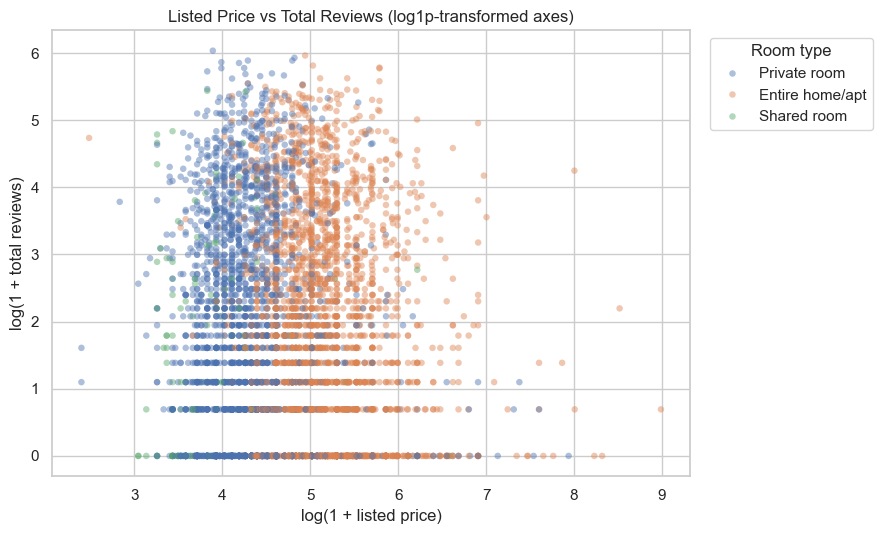

Interpretation note: reviews are not bookings, and this chart does not imply causation.


In [23]:
# Price vs total reviews. log1p transforms keep zero-review listings in the chart.
if {"price", "number_of_reviews"}.issubset(df_analysis.columns):
    scatter_df = df_analysis.loc[
        df_analysis["price"].notna() & (df_analysis["price"] > 0)
        & df_analysis["number_of_reviews"].notna()
    ].copy()
    if len(scatter_df) > 5000:
        scatter_df = scatter_df.sample(5000, random_state=42)
    scatter_df["log_price"] = np.log1p(scatter_df["price"])
    scatter_df["log_reviews"] = np.log1p(scatter_df["number_of_reviews"])
    plt.figure(figsize=(9, 5.5))
    sns.scatterplot(
        data=scatter_df, x="log_price", y="log_reviews",
        hue="room_type" if "room_type" in scatter_df.columns else None,
        alpha=0.45, s=22, linewidth=0
    )
    plt.title("Listed Price vs Total Reviews (log1p-transformed axes)")
    plt.xlabel("log(1 + listed price)")
    plt.ylabel("log(1 + total reviews)")
    if "room_type" in scatter_df.columns:
        plt.legend(title="Room type", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "09_price_vs_reviews.png", dpi=180, bbox_inches="tight")
    plt.show()
    print("Interpretation note: reviews are not bookings, and this chart does not imply causation.")


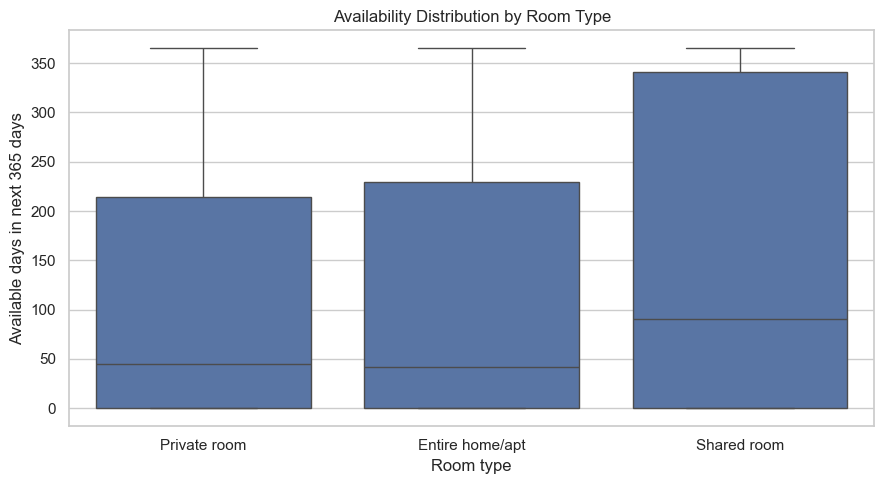

,neighbourhood_group,listing_count,median_availability,mean_availability
1,Brooklyn,20104,28.00,100.23
2,Manhattan,21661,36.00,111.98
3,Queens,5666,98.00,144.45
0,Bronx,1091,148.00,165.76
4,Staten Island,373,219.00,199.68


In [24]:
# Availability by room type / borough
if {"availability_365", "room_type"}.issubset(df_analysis.columns):
    plt.figure(figsize=(9, 5))
    sns.boxplot(data=df_analysis, x="room_type", y="availability_365")
    plt.title("Availability Distribution by Room Type")
    plt.xlabel("Room type")
    plt.ylabel("Available days in next 365 days")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "10_availability_by_room_type.png", dpi=180, bbox_inches="tight")
    plt.show()

if {"availability_365", "neighbourhood_group"}.issubset(df_analysis.columns):
    availability_summary = (
        df_analysis.groupby("neighbourhood_group", dropna=False)
        .agg(
            listing_count=("availability_365", "size"),
            median_availability=("availability_365", "median"),
            mean_availability=("availability_365", "mean")
        )
        .reset_index()
        .sort_values("median_availability")
    )
    display(availability_summary)

### 6.4 Host portfolio analysis

,host_id,host_name,calculated_host_listings_count
38293,219517861,Sonder (NYC),327
26137,107434423,Blueground,232
9740,30283594,Kara,121
32718,137358866,Kazuya,103
5093,16098958,Jeremy & Laura,96
30637,12243051,Sonder,96
14682,61391963,Corporate Housing,91
15865,22541573,Ken,87
34010,200380610,Pranjal,65
2631,7503643,Vida,52


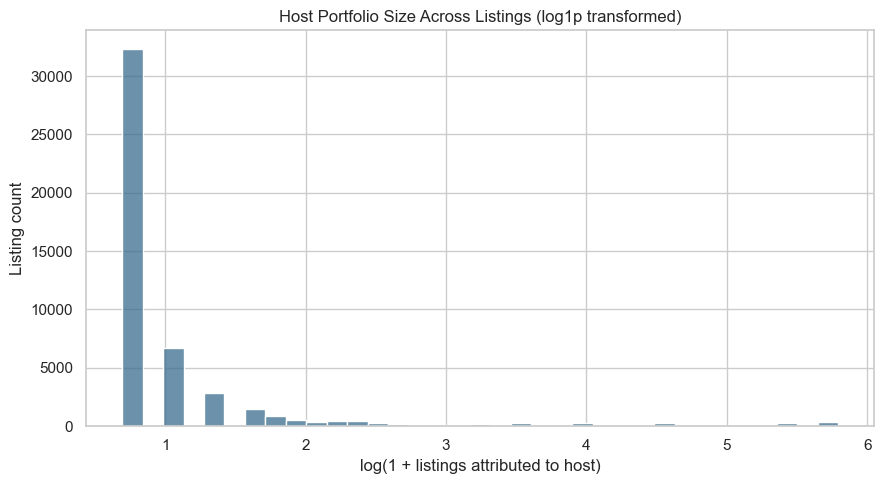

Note: this is listing-weighted, not a count of unique hosts in each bin.


,host_portfolio_segment,listing_count,median_price,median_reviews,median_availability
0,1 listing,32303,119.00,4.00,6.00
1,2–5 listings,11796,85.00,12.00,116.00
2,6–10 listings,1829,75.00,6.00,272.00
3,11+ listings,2967,175.00,1.00,317.00


In [25]:
if "calculated_host_listings_count" in df_analysis.columns:
    host_listing_counts = (
        df_analysis[["host_id", "host_name", "calculated_host_listings_count"]]
        .drop_duplicates()
        if {"host_id", "host_name"}.issubset(df_analysis.columns)
        else df_analysis[["calculated_host_listings_count"]].drop_duplicates()
    )
    display(host_listing_counts.sort_values("calculated_host_listings_count", ascending=False).head(15))

    # Each listing row inherits the host's portfolio count, so this is listing-weighted.
    portfolio_values = df_analysis["calculated_host_listings_count"].dropna()
    plt.figure(figsize=(9, 5))
    sns.histplot(np.log1p(portfolio_values), bins=35, color="#3B6C8E")
    plt.title("Host Portfolio Size Across Listings (log1p transformed)")
    plt.xlabel("log(1 + listings attributed to host)")
    plt.ylabel("Listing count")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "11_host_portfolio_distribution.png", dpi=180, bbox_inches="tight")
    plt.show()
    print("Note: this is listing-weighted, not a count of unique hosts in each bin.")

if "host_portfolio_segment" in df_analysis.columns:
    portfolio_summary = (
        df_analysis.groupby("host_portfolio_segment", observed=False, dropna=False)
        .agg(
            listing_count=("id", "size") if "id" in df_analysis.columns else ("price", "size"),
            median_price=("price", "median") if "price" in df_analysis.columns else ("calculated_host_listings_count", "median"),
            median_reviews=("number_of_reviews", "median") if "number_of_reviews" in df_analysis.columns else ("calculated_host_listings_count", "median"),
            median_availability=("availability_365", "median") if "availability_365" in df_analysis.columns else ("calculated_host_listings_count", "median")
        )
        .reset_index()
    )
    display(portfolio_summary)


### 6.5 Geographic distribution

The plot uses only the latitude and longitude fields provided in the CSV. It is a coordinate scatter plot, not a basemap and not a substitute for geographic boundary data.

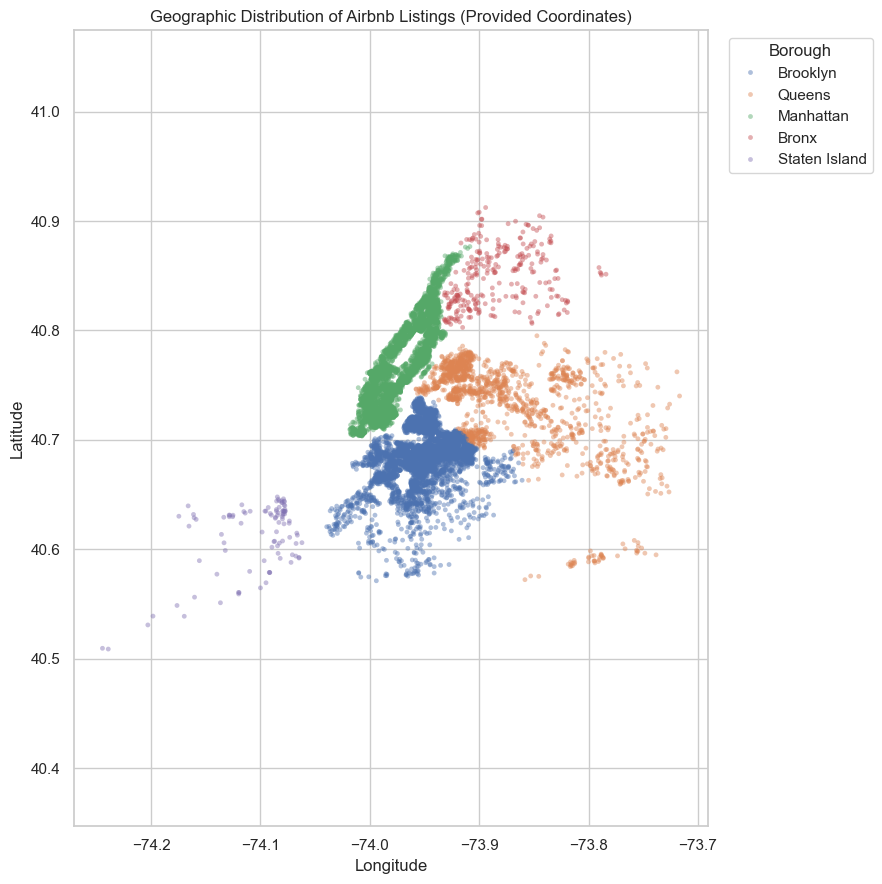

Geographic plot uses only the dataset coordinates; no external geographic dataset was added.


In [26]:
# A simple coordinate scatter plot using only latitude and longitude in the provided dataset.
# This is a point map, not a basemap; it avoids relying on external map tiles or other datasets.
if {"latitude", "longitude"}.issubset(df_analysis.columns):
    geo_df = df_analysis.dropna(subset=["latitude", "longitude"]).copy()
    geo_df = geo_df[
        geo_df["latitude"].between(-90, 90) & geo_df["longitude"].between(-180, 180)
    ]
    if len(geo_df) > 12000:
        geo_df = geo_df.sample(12000, random_state=42)

    plt.figure(figsize=(9, 9))
    if "neighbourhood_group" in geo_df.columns:
        sns.scatterplot(
            data=geo_df, x="longitude", y="latitude",
            hue="neighbourhood_group", alpha=0.45, s=12, linewidth=0
        )
        plt.legend(title="Borough", bbox_to_anchor=(1.02, 1), loc="upper left")
    else:
        plt.scatter(geo_df["longitude"], geo_df["latitude"], alpha=0.4, s=10)
    plt.title("Geographic Distribution of Airbnb Listings (Provided Coordinates)")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.axis("equal")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "12_geographic_distribution.png", dpi=180, bbox_inches="tight")
    plt.show()
    print("Geographic plot uses only the dataset coordinates; no external geographic dataset was added.")

### 6.6 Correlation and relationships

,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,latitude,longitude
price,1.00,0.10,-0.05,-0.02,-0.11,0.09,0.14,-0.44
minimum_nights,0.10,1.00,-0.17,-0.29,0.06,0.08,0.02,-0.12
number_of_reviews,-0.05,-0.17,1.00,0.71,0.06,0.24,-0.04,0.08
reviews_per_month,-0.02,-0.29,0.71,1.00,0.15,0.39,-0.02,0.12
calculated_host_listings_count,-0.11,0.06,0.06,0.15,1.00,0.41,0.00,0.06
availability_365,0.09,0.08,0.24,0.39,0.41,1.00,-0.01,0.07
latitude,0.14,0.02,-0.04,-0.02,0.00,-0.01,1.00,0.04
longitude,-0.44,-0.12,0.08,0.12,0.06,0.07,0.04,1.00


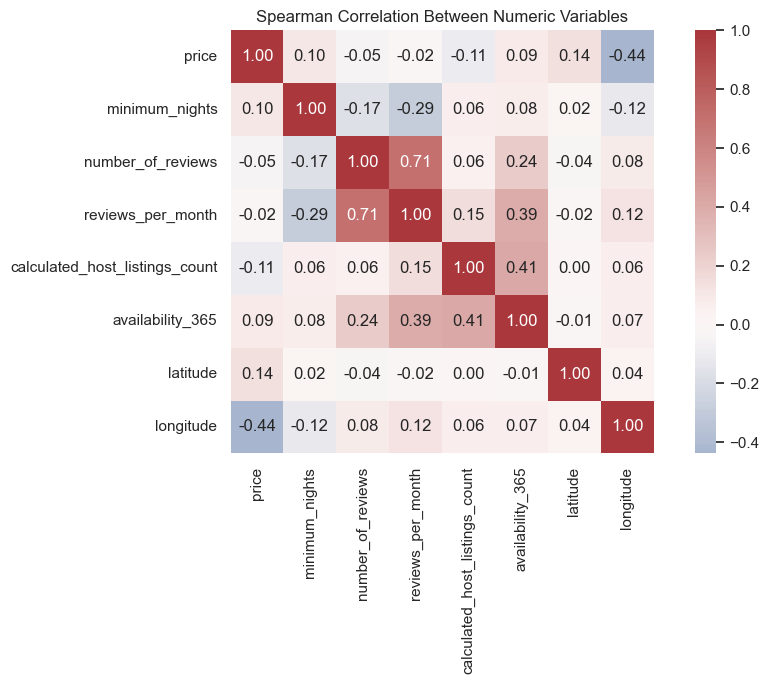

In [27]:
# Correlations are exploratory associations; they do not prove causation.
candidate_numeric = [
    c for c in [
        "price", "minimum_nights", "number_of_reviews", "reviews_per_month",
        "calculated_host_listings_count", "availability_365", "latitude", "longitude"
    ] if c in df_analysis.columns
]
corr_df = df_analysis[candidate_numeric].copy()
if "price" in corr_df.columns:
    corr_df = corr_df[corr_df["price"] > 0]

if len(candidate_numeric) >= 2:
    corr = corr_df.corr(numeric_only=True, method="spearman")
    display(corr)

    plt.figure(figsize=(10, 7))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
    plt.title("Spearman Correlation Between Numeric Variables")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "13_spearman_correlation.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("Not enough numeric columns for a correlation matrix.")

## 7. Robustness checks

Compare the price distribution with and without the upper tail. This demonstrates how extreme values affect the **mean** more than the **median**. No records are deleted for this check, and percentile-limited views must be labelled clearly.

In [28]:
if "price" in df_analysis.columns:
    positive_price_df = df_analysis.loc[df_analysis["price"] > 0].copy()
    if len(positive_price_df):
        p95 = positive_price_df["price"].quantile(0.95)
        p99 = positive_price_df["price"].quantile(0.99)
        comparison = pd.DataFrame({
            "view": ["All positive prices", "Prices at or below 99th percentile", "Prices at or below 95th percentile"],
            "rows": [
                len(positive_price_df),
                int((positive_price_df["price"] <= p99).sum()),
                int((positive_price_df["price"] <= p95).sum())
            ],
            "mean_price": [
                positive_price_df["price"].mean(),
                positive_price_df.loc[positive_price_df["price"] <= p99, "price"].mean(),
                positive_price_df.loc[positive_price_df["price"] <= p95, "price"].mean()
            ],
            "median_price": [
                positive_price_df["price"].median(),
                positive_price_df.loc[positive_price_df["price"] <= p99, "price"].median(),
                positive_price_df.loc[positive_price_df["price"] <= p95, "price"].median()
            ]
        })
        display(comparison)
        print("Use the median as a robust summary and disclose any trimmed view used in charts.")

,view,rows,mean_price,median_price
0,All positive prices,48884,152.76,106.00
1,Prices at or below 99th percentile,48410,137.58,105.00
2,Prices at or below 95th percentile,46443,122.61,100.00


Use the median as a robust summary and disclose any trimmed view used in charts.


## 8. Automatically generated summary tables

These tables are intended to help you identify findings after reviewing the charts. They do not automatically label a result as good, bad, or causal.

In [29]:
# Room-type summary
if {"room_type", "price"}.issubset(df_analysis.columns):
    room_summary = (
        df_analysis.groupby("room_type", dropna=False)
        .agg(
            listing_count=("price", "size"),
            median_price=("price", "median"),
            mean_price=("price", "mean"),
            median_reviews=("number_of_reviews", "median") if "number_of_reviews" in df_analysis.columns else ("price", "median"),
            median_reviews_per_month=("reviews_per_month", "median") if "reviews_per_month" in df_analysis.columns else ("price", "median"),
            median_availability=("availability_365", "median") if "availability_365" in df_analysis.columns else ("price", "median")
        )
        .reset_index()
        .sort_values("listing_count", ascending=False)
    )
    display(room_summary)
    room_summary.to_csv(OUTPUT_DIR / "room_type_summary.csv", index=False)

,room_type,listing_count,median_price,mean_price,median_reviews,median_reviews_per_month,median_availability
0,Entire home/apt,25409,160.00,211.79,5.00,0.66,42.00
1,Private room,22326,70.00,89.78,5.00,0.77,45.00
2,Shared room,1160,45.00,70.13,4.00,0.98,90.00


In [30]:
# Review-activity and price summary by borough / room type.
summary_group_cols = [c for c in ["neighbourhood_group", "room_type"] if c in df_analysis.columns]
if summary_group_cols and "price" in df_analysis.columns:
    segment_summary = (
        df_analysis.loc[df_analysis["price"] > 0]
        .groupby(summary_group_cols, dropna=False)
        .agg(
            listing_count=("price", "size"),
            median_price=("price", "median"),
            median_reviews=("number_of_reviews", "median") if "number_of_reviews" in df_analysis.columns else ("price", "median"),
            median_reviews_per_month=("reviews_per_month", "median") if "reviews_per_month" in df_analysis.columns else ("price", "median"),
            median_availability=("availability_365", "median") if "availability_365" in df_analysis.columns else ("price", "median")
        )
        .reset_index()
        .sort_values("listing_count", ascending=False)
    )
    display(segment_summary)
    segment_summary.to_csv(OUTPUT_DIR / "borough_room_type_summary.csv", index=False)

,neighbourhood_group,room_type,listing_count,median_price,median_reviews,median_reviews_per_month,median_availability
6,Manhattan,Entire home/apt,13198,191.00,4.00,0.53,42.00
4,Brooklyn,Private room,10126,65.00,4.00,0.63,24.00
3,Brooklyn,Entire home/apt,9558,145.00,7.00,0.68,28.00
7,Manhattan,Private room,7982,90.00,5.00,0.75,29.00
10,Queens,Private room,3372,60.00,7.00,1.17,108.00
9,Queens,Entire home/apt,2096,120.00,8.00,1.33,89.00
1,Bronx,Private room,651,54.00,9.00,1.19,158.00
8,Manhattan,Shared room,480,69.00,6.00,1.30,81.00
5,Brooklyn,Shared room,411,36.00,3.00,0.76,156.00
0,Bronx,Entire home/apt,379,100.00,11.00,1.94,131.00


## 9. Evidence-based finding prompts

Use the computed summaries and charts to complete the report. Do not state that price causes review activity, that availability equals occupancy, or that listing count equals revenue. Every final insight should name the metric, comparison, and limitation.

## 9.1 Automatically generated evidence summary

The following cell calculates a small set of defensible descriptive findings from the loaded dataset. Treat them as a starting point for the report; add context and limitations rather than copying numbers without interpretation.

In [31]:
# Generate evidence-backed findings from the actual data loaded in this run.
findings = []

if {"neighbourhood_group", "id"}.issubset(df_analysis.columns):
    borough_counts_actual = df_analysis.groupby("neighbourhood_group")["id"].count().sort_values(ascending=False)
    findings.append({
        "theme": "Supply concentration",
        "finding": f"{borough_counts_actual.index[0]} has the largest number of listings ({int(borough_counts_actual.iloc[0]):,}).",
        "metric": "Listing count",
        "caveat": "Listing count describes supply in this dataset, not bookings or revenue."
    })

if {"room_type", "id"}.issubset(df_analysis.columns):
    room_counts_actual = df_analysis.groupby("room_type")["id"].count().sort_values(ascending=False)
    findings.append({
        "theme": "Room-type mix",
        "finding": f"{room_counts_actual.index[0]} is the most common room type ({int(room_counts_actual.iloc[0]):,} listings; {room_counts_actual.iloc[0] / len(df_analysis) * 100:.1f}% of all rows).",
        "metric": "Listing count and share",
        "caveat": "This reflects listed supply, not customer preference or occupancy."
    })

if {"neighbourhood_group", "price"}.issubset(df_analysis.columns):
    valid_price_data = df_analysis.loc[df_analysis["price"] > 0]
    borough_medians = valid_price_data.groupby("neighbourhood_group")["price"].median().sort_values(ascending=False)
    if len(borough_medians) >= 2:
        high_area, low_area = borough_medians.index[0], borough_medians.index[-1]
        high_price, low_price = float(borough_medians.iloc[0]), float(borough_medians.iloc[-1])
        findings.append({
            "theme": "Price differences",
            "finding": f"{high_area} has the highest borough median listed price (${high_price:,.0f}); {low_area} has the lowest (${low_price:,.0f}).",
            "metric": "Median listed price among positive-price listings",
            "caveat": "Price differences may reflect room type, neighborhood, property features, and other unobserved factors."
        })

if {"neighbourhood_group", "neighbourhood", "id"}.issubset(df_analysis.columns):
    neighborhood_counts_actual = (
        df_analysis.groupby(["neighbourhood_group", "neighbourhood"])["id"]
        .count().sort_values(ascending=False)
    )
    if len(neighborhood_counts_actual):
        (top_borough, top_neighborhood), top_count = neighborhood_counts_actual.index[0], int(neighborhood_counts_actual.iloc[0])
        findings.append({
            "theme": "Neighborhood concentration",
            "finding": f"{top_neighborhood} ({top_borough}) has the most listings among borough-neighborhood groups ({top_count:,}).",
            "metric": "Listing count",
            "caveat": "High listing volume does not automatically mean high profitability or performance."
        })

if {"price", "number_of_reviews"}.issubset(df_analysis.columns):
    valid_pair = df_analysis.loc[(df_analysis["price"] > 0) & df_analysis["number_of_reviews"].notna(), ["price", "number_of_reviews"]]
    if len(valid_pair) > 2:
        rho = valid_pair.corr(method="spearman").iloc[0, 1]
        findings.append({
            "theme": "Price and review association",
            "finding": f"The Spearman correlation between listed price and total reviews is {rho:.2f}.",
            "metric": "Spearman correlation",
            "caveat": "Association is not causation; review counts are affected by listing age and other factors."
        })

findings_df = pd.DataFrame(findings)
display(findings_df)
findings_df.to_csv("airbnb_nyc_key_findings.csv", index=False)
print("Use these as evidence prompts; review the charts and limitations before finalizing business recommendations.")


,theme,finding,metric,caveat
0,Supply concentration,Manhattan has the largest number of listings (...,Listing count,Listing count describes supply in this dataset...
1,Room-type mix,Entire home/apt is the most common room type (...,Listing count and share,"This reflects listed supply, not customer pref..."
2,Price differences,Manhattan has the highest borough median liste...,Median listed price among positive-price listings,"Price differences may reflect room type, neigh..."
3,Neighborhood concentration,Williamsburg (Brooklyn) has the most listings ...,Listing count,High listing volume does not automatically mea...
4,Price and review association,The Spearman correlation between listed price ...,Spearman correlation,Association is not causation; review counts ar...


Use these as evidence prompts; review the charts and limitations before finalizing business recommendations.


## 10. Export cleaned data and analysis files

This section exports the cleaned dataset, cleaning log, data dictionary, missing-value report, quality report, and dashboard-ready summary tables. Files are saved in the working directory, and charts are saved in `airbnb_nyc_outputs/`.

In [32]:
# Save primary deliverables in the working directory and copy dashboard-ready tables into the output folder.
cleaned_path = Path("airbnb_nyc_cleaned.csv")
df_clean.to_csv(cleaned_path, index=False)

pd.DataFrame(cleaning_log).to_csv("airbnb_nyc_cleaning_log.csv", index=False)
column_dictionary_df.to_csv("airbnb_nyc_column_dictionary.csv", index=False)
missing_report.to_csv("airbnb_nyc_missing_values.csv", index=True)
quality_report.to_csv("airbnb_nyc_data_quality_report.csv", index=True)

# Create/re-create summary tables reliably for Power BI and the report.
positive_price_df = df_analysis.loc[df_analysis["price"] > 0].copy() if "price" in df_analysis.columns else df_analysis.copy()

if {"neighbourhood_group", "id"}.issubset(df_analysis.columns):
    borough_summary_export = df_analysis.groupby("neighbourhood_group", dropna=False).agg(
        listing_count=("id", "count"),
        median_availability=("availability_365", "median") if "availability_365" in df_analysis.columns else ("id", "count"),
        mean_availability=("availability_365", "mean") if "availability_365" in df_analysis.columns else ("id", "mean")
    ).reset_index()
    if "price" in positive_price_df.columns:
        price_summary_export = positive_price_df.groupby("neighbourhood_group", dropna=False)["price"].agg(
            median_price="median", mean_price="mean", p75_price=lambda s: s.quantile(.75), p90_price=lambda s: s.quantile(.90)
        ).reset_index()
        borough_summary_export = borough_summary_export.merge(price_summary_export, on="neighbourhood_group", how="left")
    borough_summary_export.to_csv("airbnb_nyc_borough_summary.csv", index=False)

if {"neighbourhood_group", "neighbourhood", "id"}.issubset(df_analysis.columns):
    agg_dict = {"id": "count"}
    if "price" in positive_price_df.columns:
        neighborhood_summary_export = positive_price_df.groupby(
            ["neighbourhood_group", "neighbourhood"], dropna=False
        ).agg(
            listing_count=("id", "count"),
            median_price=("price", "median"),
            mean_price=("price", "mean"),
            median_reviews=("number_of_reviews", "median") if "number_of_reviews" in df_analysis.columns else ("price", "median"),
            median_availability=("availability_365", "median") if "availability_365" in df_analysis.columns else ("price", "median")
        ).reset_index()
    else:
        neighborhood_summary_export = df_analysis.groupby(
            ["neighbourhood_group", "neighbourhood"], dropna=False
        ).agg(listing_count=("id", "count")).reset_index()
    neighborhood_summary_export.to_csv("airbnb_nyc_neighborhood_summary.csv", index=False)

# Save common analysis tables into the charts/output folder as well.
for filename in [
    "airbnb_nyc_cleaned.csv", "airbnb_nyc_cleaning_log.csv",
    "airbnb_nyc_column_dictionary.csv", "airbnb_nyc_missing_values.csv",
    "airbnb_nyc_data_quality_report.csv", "airbnb_nyc_borough_summary.csv",
    "airbnb_nyc_neighborhood_summary.csv", "airbnb_nyc_key_findings.csv"
]:
    p = Path(filename)
    if p.exists():
        p.replace(OUTPUT_DIR / filename)

# Put a copy of the cleaned dataset in the root for easy Power BI import.
# Restore the root copy if the previous loop moved it into the output folder.
if not Path("airbnb_nyc_cleaned.csv").exists() and (OUTPUT_DIR / "airbnb_nyc_cleaned.csv").exists():
    import shutil
    shutil.copy2(OUTPUT_DIR / "airbnb_nyc_cleaned.csv", "airbnb_nyc_cleaned.csv")

print("Export verification:")
for p in [
    Path("airbnb_nyc_cleaned.csv"),
    OUTPUT_DIR / "airbnb_nyc_cleaned.csv",
    OUTPUT_DIR / "airbnb_nyc_cleaning_log.csv",
    OUTPUT_DIR / "airbnb_nyc_column_dictionary.csv",
    OUTPUT_DIR / "airbnb_nyc_missing_values.csv",
    OUTPUT_DIR / "airbnb_nyc_data_quality_report.csv",
    OUTPUT_DIR / "airbnb_nyc_borough_summary.csv",
    OUTPUT_DIR / "airbnb_nyc_neighborhood_summary.csv",
    OUTPUT_DIR / "airbnb_nyc_key_findings.csv"
]:
    print(f" - {p}: {'OK' if p.exists() else 'MISSING'}")


Export verification:
 - airbnb_nyc_cleaned.csv: OK
 - airbnb_nyc_outputs\airbnb_nyc_cleaned.csv: OK
 - airbnb_nyc_outputs\airbnb_nyc_cleaning_log.csv: OK
 - airbnb_nyc_outputs\airbnb_nyc_column_dictionary.csv: OK
 - airbnb_nyc_outputs\airbnb_nyc_missing_values.csv: OK
 - airbnb_nyc_outputs\airbnb_nyc_data_quality_report.csv: OK
 - airbnb_nyc_outputs\airbnb_nyc_borough_summary.csv: OK
 - airbnb_nyc_outputs\airbnb_nyc_neighborhood_summary.csv: OK
 - airbnb_nyc_outputs\airbnb_nyc_key_findings.csv: OK


In [33]:
# List charts created during this run.
chart_files = sorted(OUTPUT_DIR.glob("*.png"))
print(f"Charts created: {len(chart_files)}")
for chart in chart_files:
    print(" -", chart)

Charts created: 13
 - airbnb_nyc_outputs\01_listings_by_borough.png
 - airbnb_nyc_outputs\02_room_type_distribution.png
 - airbnb_nyc_outputs\03_price_distribution.png
 - airbnb_nyc_outputs\04_median_price_by_borough.png
 - airbnb_nyc_outputs\05_price_by_borough_and_room_type.png
 - airbnb_nyc_outputs\06_top_neighborhoods_by_count.png
 - airbnb_nyc_outputs\07_number_of_reviews_distribution.png
 - airbnb_nyc_outputs\08_reviews_per_month_distribution.png
 - airbnb_nyc_outputs\09_price_vs_reviews.png
 - airbnb_nyc_outputs\10_availability_by_room_type.png
 - airbnb_nyc_outputs\11_host_portfolio_distribution.png
 - airbnb_nyc_outputs\12_geographic_distribution.png
 - airbnb_nyc_outputs\13_spearman_correlation.png
